   # Credit Card Fraud Analytics
   A project on detecting rare fraudulent card payments, like the mobile money and card fraud that banks face in Kenya.

In [1]:
   import warnings
   import numpy as np
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns

   warnings.filterwarnings("ignore")
   sns.set_theme(style="whitegrid")

   DATA_PATH = "data/creditcard.csv"

Matplotlib is building the font cache; this may take a moment.


In [2]:
   df = pd.read_csv(DATA_PATH)
   print("Rows and columns:", df.shape)
   df.head()

Rows and columns: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Check the data
Looking for missing values, duplicate rows and unusual numbers before we analyse anything.

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Time span (hours):", round(df["Time"].max() / 3600, 1))
df[["Time", "Amount", "Class"]].describe().T

Missing values: 0
Duplicate rows: 1081
Time span (hours): 48.0


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


In [4]:
print(df.isna().shape)        # (284807, 31) a table
print(df.duplicated().shape)  # (284807,) a single column

(284807, 31)
(284807,)


In [5]:
df[df.duplicated(keep=False)].sort_values("Time").head(6)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [6]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows -> {len(df):,} transactions remain")

Dropped 1081 duplicate rows -> 283,726 transactions remain


## 2. How rare is fraud?
Counting fraud against legitimate payments. If fraud is very rare, a model can look accurate while catching almost none of it.

Legitimate: 283,253
Fraud:      473
Fraud rate: 0.167%
About 1 fraud in every 600 transactions


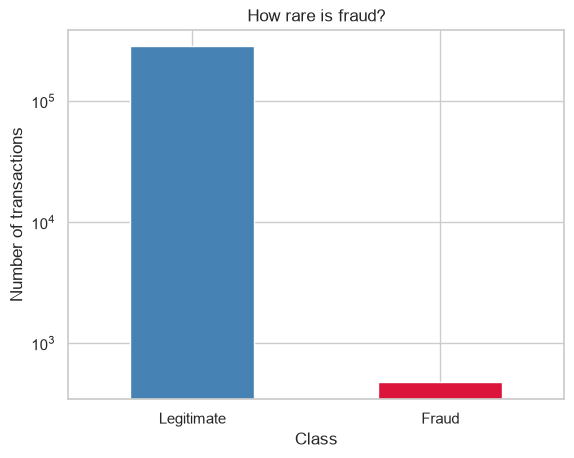

In [8]:
counts = df["Class"].value_counts()
fraud_rate = counts[1] / len(df) * 100

print(f"Legitimate: {counts[0]:,}")
print(f"Fraud:      {counts[1]:,}")
print(f"Fraud rate: {fraud_rate:.3f}%")
print(f"About 1 fraud in every {len(df) / counts[1]:.0f} transactions")

ax = counts.rename({0: "Legitimate", 1: "Fraud"}).plot(kind="bar", color=["steelblue", "crimson"])
ax.set_title("How rare is fraud?")
ax.set_ylabel("Number of transactions")
plt.xticks(rotation=0)
ax.set_yscale("log")
plt.show()

## 3. Do fraud payments look different?
Comparing the amounts of fraud and legitimate payments to see if fraud has a pattern.

In [9]:
df.groupby("Class")["Amount"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87
